# BrandPulse · Phase 1 — Data validity, reusable KPIs and brand-centric EDA

**Dataset:** Brand Intelligence Accelerator v1 (2024-01-01 → 2025-12-30) · 20,440 transactions · 55 SKUs · 11 brands · 3 manufacturers

**Scope:** the 5 Reckitt brands (Dettol, Harpic, Veet, Mortein, Lizol) are the **core brands**. The 6 Unilever and P&G brands (Ariel, Domex, Gillette, Head & Shoulders, Lifebuoy, Lux) are **competitors**.

Every number in this notebook comes from the shared KPI engine (`kpi/engine.py`), the same code the dashboard and the Q&A assistant use.

**Contents**
1. Data validity checks
2. The data model
3. Reusable KPIs and Time Intelligence
4. Univariate view of the transactions
5. Brand-centric period-wise sales
6. Bivariate analysis
7. Multivariate analysis
8. Competitive landscape preview (SubCategory rule)
9. Brand Health Score
10. Key findings

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

from pipeline.build_model import load_model
from pipeline.schema import CORE_BRANDS
from kpi.engine import Engine
from kpi.filters import Filters
from kpi import registry as R, time_intel as T
from kpi.health_score import health_scores

pd.set_option("display.width", 160, "display.max_columns", 30, "display.float_format", "{:,.2f}".format)
eng = Engine(load_model(rebuild=True))
m = eng.m
S = m.sales

# Visual language used in every chart: core brands saturated + solid, competitors muted + dashed
CORE_COLORS = {"Dettol": "#1F6FB2", "Harpic": "#13917A", "Veet": "#C2417F", "Mortein": "#D9741F", "Lizol": "#6B4FBB"}
COMP_COLORS = {"Ariel": "#9AA5B1", "Domex": "#B08F7A", "Gillette": "#8E9C8A", "Head & Shoulders": "#A79AB5",
               "Lifebuoy": "#B5A27A", "Lux": "#9FB0B8"}
BRAND_COLORS = {**CORE_COLORS, **COMP_COLORS}
BRANDS = CORE_BRANDS + sorted(COMP_COLORS)
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
inr = mtick.FuncFormatter(lambda x, _: f"₹{x/1e6:.1f}M" if abs(x) >= 1e6 else f"₹{x/1e3:.0f}K")
print(f"{len(S):,} transactions, {S['Date'].min().date()} → {S['Date'].max().date()}")

20,440 transactions, 2024-01-01 → 2025-12-30


## 1. Data validity checks

`pipeline/validate.py` runs 46 checks covering primary keys, nulls, foreign keys, arithmetic identities, value ranges, promotion consistency, calendar coverage and coverage gaps. Each check has a severity: **error** means the data is wrong, **warning** means a gap the dashboard must label, and **info** means a structural fact worth knowing.

In [2]:
from pipeline.ingest import load_workbook
from pipeline.validate import run_checks, summarize
results = run_checks(load_workbook())
print(summarize(results))
vr = pd.DataFrame([r.__dict__ for r in results]).drop(columns="sample")
vr["result"] = np.where(vr["passed"], "pass", vr["severity"])
vr.groupby(["result"]).size()

{'checks': 46, 'errors': 0, 'warnings': 4, 'info': 4, 'status': 'pass'}


result
info        2
pass       40
warning     4
dtype: int64

In [3]:
# Everything that is not a clean pass: these become labelled caveats in the dashboard and Q&A
vr[vr["result"] != "pass"][["severity", "check", "sheet", "detail"]].style.hide(axis="index")

severity,check,sheet,detail
warning,calendar_complete,Dim_Date,Calendar should cover every day of each year. Missing: 2025-12-31. Year-end comparisons treat the last year as ending one day early.
warning,market_share_coverage,Fact_MarketShare,"Market share exists for 6 of 11 brands. Missing: Gillette, Head & Shoulders, Lizol, Lux, Mortein. Core brands without share: Lizol, Mortein."
warning,marketing_has_no_brand,Fact_Marketing,Fact_Marketing has no Brand column: campaign spend and ROI can only be reported for the company as a whole.
warning,competitor_events_are_manufacturer_level,Fact_CompetitorEvents,"Events are recorded per manufacturer (P&G, SC Johnson, Unilever), not per brand. SC Johnson has events but no products in the data."
info,category_not_brand_consistent,Dim_Product,"11 of 11 brands have SKUs in more than one Category, so competitors are matched on SubCategory only (see docs/DECISIONS.md)."
info,review_text_templated,Fact_Reviews,"ReviewText has only 3 fixed phrases tied to rating: 2★: Average quality, Packaging leakage issue; 3★: Average quality, Packaging leakage issue; 4★: Excellent quality; 5★: Excellent quality. Only the leakage complaint adds information beyond the rating."


In [4]:
# The checks that matter most for KPI correctness, all passing
vr[vr["check"].isin(["revenue_equals_units_x_price", "margin_equals_price_minus_cost", "price_not_above_mrp",
                     "non_promo_sold_at_mrp", "promo_rows_discounted", "foreign_key", "primary_key_unique"])] \
  [["check", "sheet", "failing_rows", "detail"]].head(14).style.hide(axis="index")

check,sheet,failing_rows,detail
primary_key_unique,Dim_Product,0,ProductID must be unique
primary_key_unique,Dim_Retailer,0,RetailerID must be unique
primary_key_unique,Dim_Warehouse,0,WarehouseID must be unique
primary_key_unique,Dim_Date,0,Date must be unique
primary_key_unique,Fact_Sales,0,SalesID must be unique
primary_key_unique,Fact_Reviews,0,ReviewID must be unique
primary_key_unique,Fact_MarketShare,0,Date+Brand must be unique
foreign_key,Fact_Sales,0,Fact_Sales.ProductID must exist in Dim_Product.ProductID
foreign_key,Fact_Sales,0,Fact_Sales.RetailerID must exist in Dim_Retailer.RetailerID
foreign_key,Fact_Sales,0,Fact_Sales.WarehouseID must exist in Dim_Warehouse.WarehouseID


**What validation tells us**
- The transaction data is internally consistent: Revenue = Units × Price and Margin = (Price − UnitCost) × Units hold on every row, and every key resolves.
- Promotions are clean. Non-promo rows sell at MRP, and promo rows carry a fixed discount (Summer 10%, Festive 15%).
- Four gaps must be labelled wherever they matter: market share for only 6 brands, marketing with no brand, competitor events recorded per manufacturer, and a missing 2025-12-31.

## 2. The data model

`pipeline/build_model.py` joins the facts to their dimensions and adds derived columns (`GrossValue`, `DiscountValue`, `HasPromo`, `InPromoSeason`, `IsCore`, `BelowReorder`, `IsLeakage`).

In [5]:
pd.DataFrame({t: [len(getattr(m, t)), getattr(m, t).shape[1]] for t in
              ["sales", "reviews", "inventory", "market_share", "marketing", "events", "products", "retailers"]},
             index=["rows", "columns"]).T

,rows,columns
sales,20440,30
reviews,5104,16
inventory,20440,17
market_share,144,4
marketing,48,7
events,51,4
products,55,9
retailers,10,4


In [6]:
# Every brand has 5 SKUs. SubCategory, not Category, is what the competitor mapping uses (section 8)
pm = m.products.pivot_table(index="Brand", columns="SubCategory", values="ProductID", aggfunc="count", fill_value=0)
pm = pm.loc[BRANDS]
pm.insert(0, "Manufacturer", m.products.groupby("Brand")["Manufacturer"].first().loc[BRANDS])
pm

SubCategory,Manufacturer,Cleaner,Cream,Liquid,Soap,Spray
Brand,,,,,,
Dettol,Reckitt,3,0,1,1,0
Harpic,Reckitt,0,2,0,0,3
Veet,Reckitt,1,0,0,3,1
Mortein,Reckitt,1,3,0,0,1
Lizol,Reckitt,1,0,1,1,2
Ariel,P&G,1,1,1,1,1
Domex,Unilever,1,0,1,1,2
Gillette,P&G,1,2,0,1,1
Head & Shoulders,P&G,0,1,1,3,0


In [7]:
# Promotions run in two fixed seasons. That matters for how promo lift is measured (section 6)
pd.crosstab(S["Date"].dt.month, S["Promotion"]).T

Date,1,2,3,4,5,6,7,8,9,10,11,12
Promotion,,,,,,,,,,,,
Festive,0,0,0,0,0,0,0,0,833,862,832,0
None,1736,1596,1152,1090,1134,1680,1736,1736,847,874,848,1708
Summer,0,0,584,590,602,0,0,0,0,0,0,0


## 3. Reusable KPIs and Time Intelligence

Every KPI is declared once in `kpi/registry.py`. Ratios are built from summed measures, so they aggregate correctly at any grain: ASP is total revenue / total units, never an average of averages. Every KPI works with every Time Intelligence preset and comparison mode.

In [8]:
R.catalog()[["id", "name", "group", "unit", "source", "formula_text"]].style.hide(axis="index")

id,name,group,unit,source,formula_text
revenue,Total Revenue,Revenue,currency,sales,SUM(Revenue)
revenue_growth_pct,Revenue Growth %,Revenue,pct,sales,(Revenue - Revenue_prev) / Revenue_prev x 100
units,Units Sold,Volume,count,sales,SUM(UnitsSold)
unit_growth_pct,Unit Growth %,Volume,pct,sales,(Units - Units_prev) / Units_prev x 100
asp,Average Selling Price,Volume,currency,sales,SUM(Revenue) / SUM(UnitsSold)
transactions,Transactions,Volume,count,sales,COUNT(SalesID)
margin,Gross Margin,Financial,currency,sales,SUM(Margin)
margin_pct,Margin %,Financial,pct,sales,SUM(Margin) / SUM(Revenue) x 100
discount_pct,Discount %,Pricing,pct,sales,SUM(Units x MRP - Revenue) / SUM(Units x MRP) x 100
price_index,Price Index,Pricing,index,sales,SUM(Revenue) / SUM(Units x SKU avg price) x 100


In [9]:
# Time Intelligence presets, resolved at the last data date
rows = []
for p in T.PRESETS:
    per, _ = eng.period(p)
    prv = eng.comparison_period(p, "previous")
    yoy = eng.comparison_period(p, "yoy")
    rows.append([p, T.PRESETS[p], per.start.date(), per.end.date(), per.days,
                 f"{prv.start.date()} → {prv.end.date()}", f"{yoy.start.date()} → {yoy.end.date()}"])
pd.DataFrame(rows, columns=["preset", "meaning", "start", "end", "days", "previous period", "same period last year"])

,preset,meaning,start,end,days,previous period,same period last year
0,WTD,Week to date,2025-12-29,2025-12-30,2,2025-12-27 → 2025-12-28,2024-12-29 → 2024-12-30
1,MTD,Month to date,2025-12-01,2025-12-30,30,2025-11-01 → 2025-11-30,2024-12-01 → 2024-12-30
2,QTD,Quarter to date,2025-10-01,2025-12-30,91,2025-07-01 → 2025-09-29,2024-10-01 → 2024-12-30
3,YTD,Year to date,2025-01-01,2025-12-30,364,2024-01-01 → 2024-12-30,2024-01-01 → 2024-12-30
4,R7,Rolling 7 days,2025-12-24,2025-12-30,7,2025-12-17 → 2025-12-23,2024-12-24 → 2024-12-30
5,R30,Rolling 30 days,2025-12-01,2025-12-30,30,2025-11-01 → 2025-11-30,2024-12-01 → 2024-12-30
6,R90,Rolling 90 days,2025-10-02,2025-12-30,90,2025-07-04 → 2025-10-01,2024-10-02 → 2024-12-30
7,PM,Previous month,2025-11-01,2025-11-30,30,2025-10-01 → 2025-10-31,2024-11-01 → 2024-11-30
8,PQ,Previous quarter,2025-07-01,2025-09-30,92,2025-04-01 → 2025-06-30,2024-07-01 → 2024-09-30
9,L13W,Last 13 weeks,2025-10-01,2025-12-30,91,2025-07-02 → 2025-09-30,2024-10-01 → 2024-12-30


In [10]:
# One KPI across every preset: Dettol revenue, current vs. same period last year
f = Filters.make(brands="Dettol")
rows = []
for p in T.PRESETS:
    if p == "PY":
        continue
    r = eng.compare("revenue", f, p, "yoy")
    rows.append([p, r["current"], r["previous"], r["delta_pct"], r["comparison_coverage"]])
pd.DataFrame(rows, columns=["preset", "revenue", "revenue SPLY", "YoY %", "SPLY coverage"]).set_index("preset")

,revenue,revenue SPLY,YoY %,SPLY coverage
preset,,,,
WTD,"22,230.00","20,305.00",9.48,1.00
MTD,"329,750.00","348,670.00",-5.43,1.00
QTD,"1,120,210.50","1,059,366.00",5.74,1.00
YTD,"4,067,007.75","4,177,388.75",-2.64,1.00
R7,"79,430.00","58,400.00",36.01,1.00
R30,"329,750.00","348,670.00",-5.43,1.00
R90,"1,097,679.50","1,055,296.00",4.02,1.00
PM,"336,924.00","367,181.25",-8.24,1.00
PQ,"993,539.25","982,715.75",1.10,1.00


In [11]:
# A scorecard: every core brand, YTD vs. same period last year
kp = ["revenue", "units", "asp", "margin_pct", "discount_pct", "promo_revenue_share", "avg_rating", "stockout_risk_pct"]
rows = {}
for b in CORE_BRANDS:
    sc = eng.scorecard(kp, Filters.make(brands=b), "YTD", "yoy")
    rows[b] = {f"{r['kpi']}": r["current"] for r in sc} | {"revenue YoY %": sc[0]["delta_pct"], "units YoY %": sc[1]["delta_pct"]}
pd.DataFrame(rows).T

,revenue,units,asp,margin_pct,discount_pct,promo_revenue_share,avg_rating,stockout_risk_pct,revenue YoY %,units YoY %
Dettol,"4,067,007.75","69,512.00",58.51,46.50,3.11,21.28,3.41,3.22,-2.64,-0.70
Harpic,"7,892,087.60","70,712.00",111.61,44.37,3.06,20.57,3.47,2.88,-4.37,-2.23
Veet,"10,224,422.80","66,265.00",154.30,43.89,3.12,21.58,3.52,3.34,2.85,2.90
Mortein,"8,275,627.35","69,004.00",119.93,44.05,2.78,18.49,3.50,2.80,-4.32,0.09
Lizol,"9,633,878.75","67,088.00",143.60,43.75,2.85,19.98,3.54,3.11,-3.76,-1.68


## 4. Univariate view of the transactions

,count,mean,std,min,25%,50%,75%,max
UnitsSold,"20,440.00",74.87,31.86,19.00,48.00,74.00,102.00,144.00
SellingPrice,"20,440.00",126.00,68.81,38.25,55.00,95.00,199.00,249.00
Revenue,"20,440.00","9,434.17","6,854.84",855.00,"4,345.00","7,159.50","12,840.00","35,856.00"
Margin,"20,440.00","4,132.59","3,216.72",238.75,"1,743.99","3,109.57","5,624.45","18,601.92"


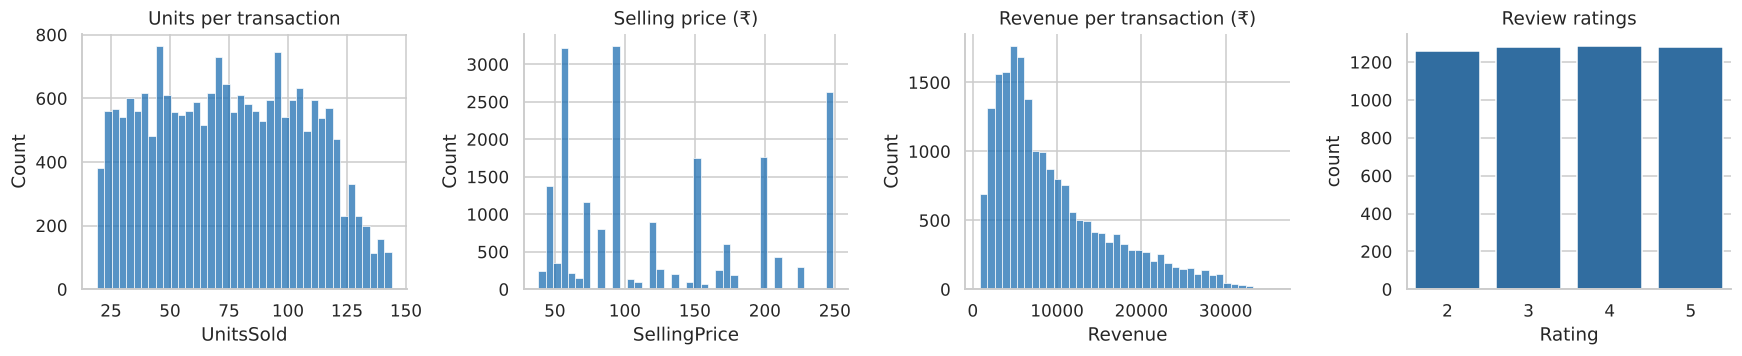

In [12]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.4))
sns.histplot(S["UnitsSold"], bins=40, ax=ax[0], color="#1F6FB2"); ax[0].set_title("Units per transaction")
sns.histplot(S["SellingPrice"], bins=40, ax=ax[1], color="#1F6FB2"); ax[1].set_title("Selling price (₹)")
sns.histplot(S["Revenue"], bins=40, ax=ax[2], color="#1F6FB2"); ax[2].set_title("Revenue per transaction (₹)")
sns.countplot(x=m.reviews["Rating"], ax=ax[3], color="#1F6FB2"); ax[3].set_title("Review ratings")
plt.tight_layout()
S[["UnitsSold", "SellingPrice", "Revenue", "Margin"]].describe().T

- Selling prices fall on a few MRP points (₹55 to ₹249), so price variation comes mostly from **which SKU** is sold, not from discounting.
- Ratings run only from 2★ to 5★ and are spread almost evenly. There are no 1★ reviews.

## 5. Brand-centric period-wise sales

This is the core of the EDA: how each brand's sales move over time, with the 5 core brands shown solid and in colour, and competitors dashed and muted.

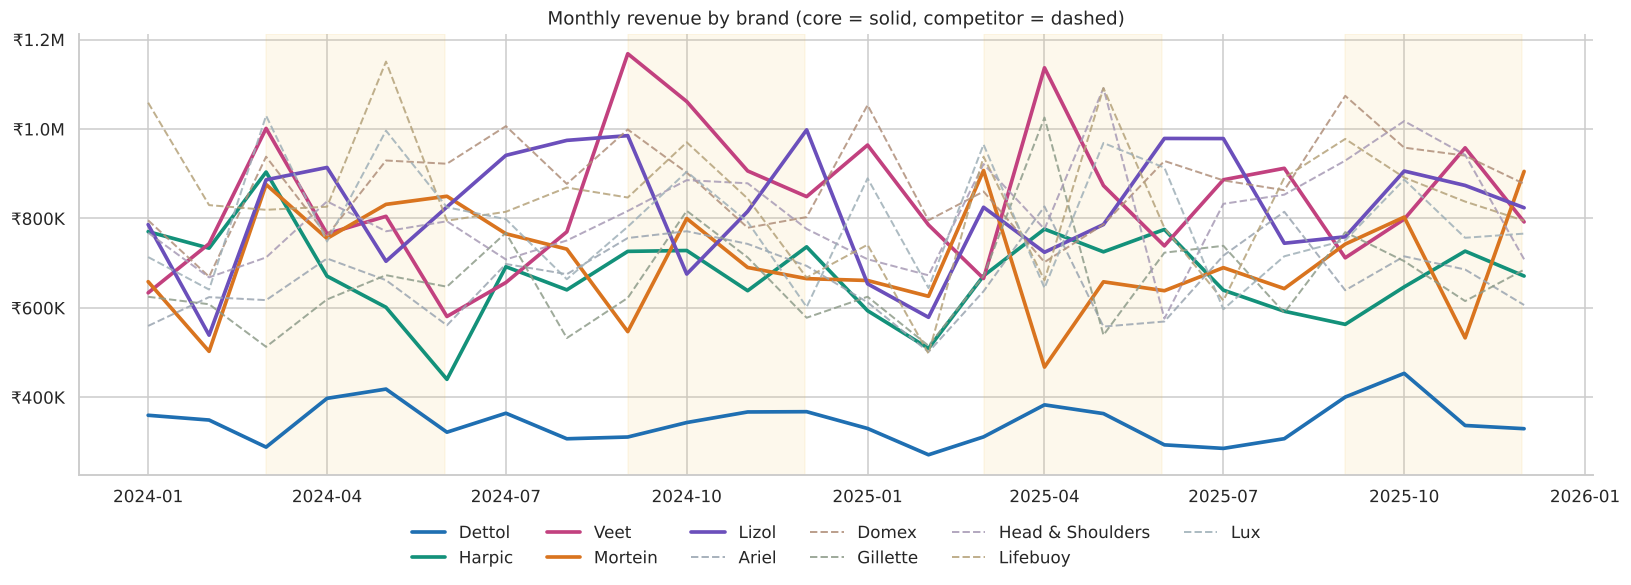

In [13]:
ts = eng.timeseries("revenue", "M", None, "ALL", by="Brand")
fig, ax = plt.subplots(figsize=(15, 5.5))
for b in BRANDS:
    d = ts[ts["Brand"] == b]
    core = b in CORE_BRANDS
    ax.plot(d["bucket"], d["value"], label=b, color=BRAND_COLORS[b], lw=2.4 if core else 1.3,
            ls="-" if core else "--", alpha=1 if core else 0.85)
ax.yaxis.set_major_formatter(inr); ax.set_title("Monthly revenue by brand (core = solid, competitor = dashed)")
for start, end, lab in [("2024-03-01", "2024-05-31", "Summer"), ("2024-09-01", "2024-11-30", "Festive"),
                         ("2025-03-01", "2025-05-31", "Summer"), ("2025-09-01", "2025-11-30", "Festive")]:
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color="#F2C14E", alpha=0.10)
ax.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.08), frameon=False)
plt.tight_layout()

In [14]:
# Year totals and YoY growth per brand (same calendar days: 1 Jan - 30 Dec)
rows = []
for b in BRANDS:
    r = eng.compare("revenue", Filters.make(brands=b), "YTD", "yoy")
    u = eng.compare("units", Filters.make(brands=b), "YTD", "yoy")
    rows.append([b, "Core" if b in CORE_BRANDS else "Competitor", r["previous"], r["current"], r["delta_pct"], u["delta_pct"]])
yoy = pd.DataFrame(rows, columns=["Brand", "Type", "Revenue 2024", "Revenue 2025", "Revenue YoY %", "Units YoY %"]).set_index("Brand")
yoy.sort_values("Revenue 2025", ascending=False)

,Type,Revenue 2024,Revenue 2025,Revenue YoY %,Units YoY %
Brand,,,,,
Domex,Competitor,"10,362,303.60","10,726,714.85",3.52,4.67
Veet,Core,"9,940,966.95","10,224,422.80",2.85,2.90
Head & Shoulders,Competitor,"9,319,990.30","10,031,429.40",7.63,2.05
Lifebuoy,Competitor,"10,455,885.55","9,719,662.75",-7.04,-8.38
Lizol,Core,"10,009,774.85","9,633,878.75",-3.76,-1.68
Lux,Competitor,"9,476,845.50","9,499,961.45",0.24,1.09
Mortein,Core,"8,649,479.35","8,275,627.35",-4.32,0.09
Gillette,Competitor,"7,715,923.15","8,202,655.50",6.31,5.04
Harpic,Core,"8,252,687.15","7,892,087.60",-4.37,-2.23


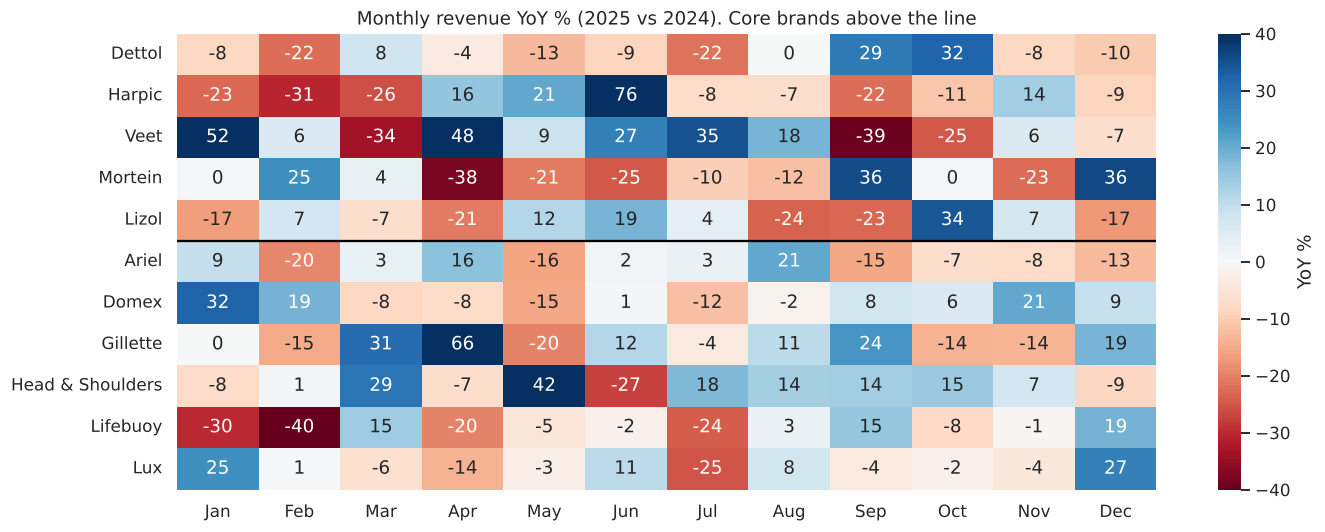

In [15]:
# Month-by-month YoY growth heatmap: where in the year each brand grew or shrank
mt = eng.timeseries("revenue", "M", None, "ALL", by="Brand")
mt["year"], mt["month"] = mt["bucket"].dt.year, mt["bucket"].dt.month
pv = mt.pivot_table(index=["Brand", "month"], columns="year", values="value").reset_index()
pv["yoy"] = 100 * (pv[2025] / pv[2024] - 1)
heat = pv.pivot(index="Brand", columns="month", values="yoy").loc[BRANDS]
heat.columns = [pd.Timestamp(2025, c, 1).strftime("%b") for c in heat.columns]
fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="RdBu", center=0, vmin=-40, vmax=40, cbar_kws={"label": "YoY %"}, ax=ax)
ax.axhline(5, color="black", lw=1.5); ax.set_title("Monthly revenue YoY % (2025 vs 2024). Core brands above the line"); ax.set_ylabel("")
plt.tight_layout()

In [16]:
# Quarterly revenue per core brand, with each quarter's share of the brand's year
q = eng.timeseries("revenue", "Q", Filters.make(brands=CORE_BRANDS), "ALL", by="Brand")
q["Quarter"] = q["bucket"].dt.year.astype(str) + "-Q" + q["bucket"].dt.quarter.astype(str)
qp = q.pivot(index="Brand", columns="Quarter", values="value").loc[CORE_BRANDS]
qp

Quarter,2024-Q1,2024-Q2,2024-Q3,2024-Q4,2025-Q1,2025-Q2,2025-Q3,2025-Q4
Brand,,,,,,,,
Dettol,"997,432.50","1,137,874.50","982,715.75","1,078,486.00","913,075.00","1,040,183.00","993,539.25","1,120,210.50"
Harpic,"2,407,952.40","1,712,405.50","2,058,857.80","2,103,260.45","1,774,780.30","2,276,967.60","1,795,281.90","2,045,057.80"
Veet,"2,378,647.50","2,151,271.60","2,595,461.35","2,816,801.50","2,415,585.80","2,749,286.90","2,510,790.85","2,548,759.25"
Mortein,"2,037,329.10","2,436,553.20","2,044,154.20","2,155,572.85","2,194,422.00","1,764,271.40","2,075,624.35","2,241,309.60"
Lizol,"2,211,808.70","2,444,162.20","2,901,168.80","2,489,741.15","2,057,809.90","2,489,811.50","2,482,369.20","2,603,888.15"


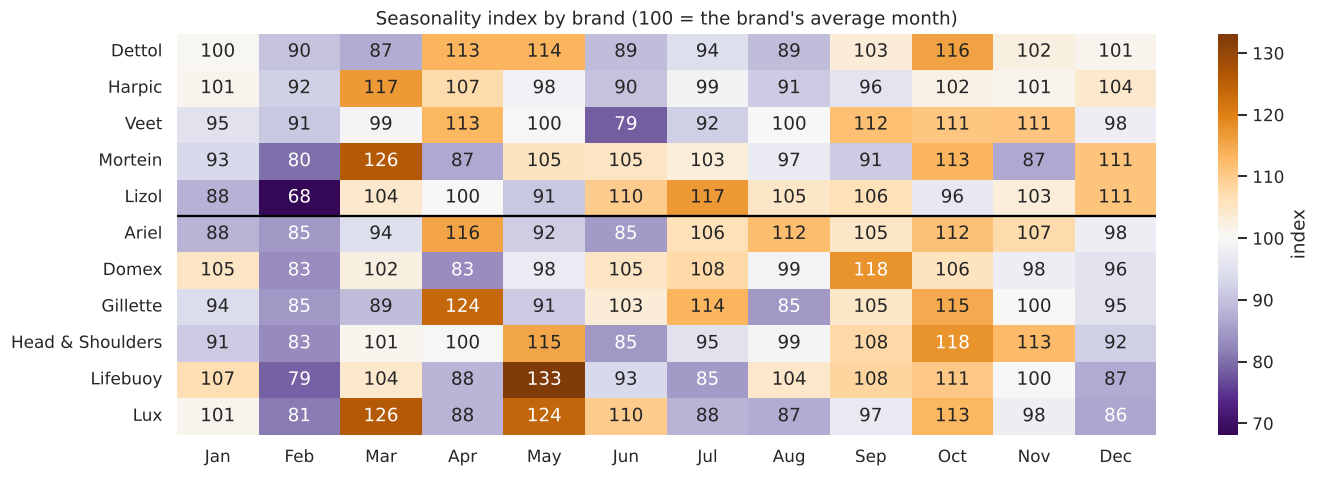

In [17]:
# Seasonality index: each month's revenue vs. the brand's average month (100 = average), both years combined
mt["month_name"] = mt["bucket"].dt.strftime("%b")
si = mt.groupby(["Brand", "month"])["value"].sum().unstack()
si = 100 * si.div(si.mean(axis=1), axis=0)
si.columns = [pd.Timestamp(2025, c, 1).strftime("%b") for c in si.columns]
fig, ax = plt.subplots(figsize=(13, 4.5))
sns.heatmap(si.loc[BRANDS], annot=True, fmt=".0f", cmap="PuOr_r", center=100, ax=ax, cbar_kws={"label": "index"})
ax.axhline(5, color="black", lw=1.5); ax.set_title("Seasonality index by brand (100 = the brand's average month)"); ax.set_ylabel("")
plt.tight_layout()

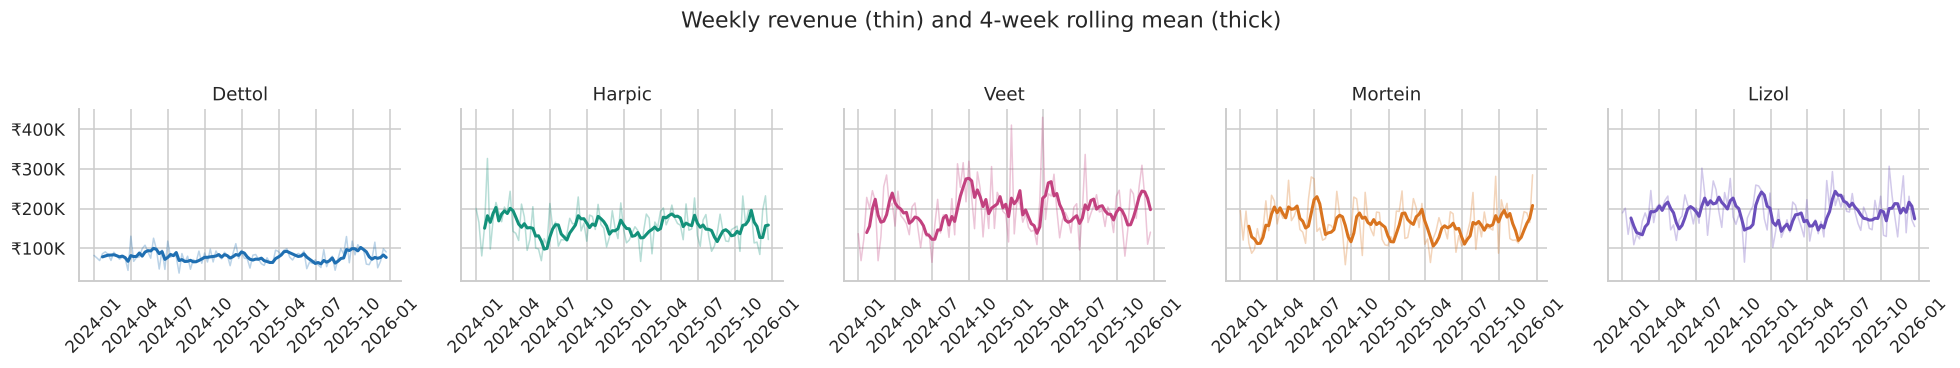

In [18]:
# Weekly revenue for the core brands with a 4-week rolling mean: the short-term noise behind the monthly trend
w = eng.timeseries("revenue", "W", Filters.make(brands=CORE_BRANDS), "ALL", by="Brand")
w = w[~w["partial"]]
fig, axes = plt.subplots(1, 5, figsize=(18, 3.2), sharey=True)
for ax, b in zip(axes, CORE_BRANDS):
    d = w[w["Brand"] == b].set_index("bucket")["value"]
    ax.plot(d.index, d, color=CORE_COLORS[b], alpha=0.3, lw=1)
    ax.plot(d.index, d.rolling(4).mean(), color=CORE_COLORS[b], lw=2)
    ax.set_title(b); ax.yaxis.set_major_formatter(inr); ax.tick_params(axis="x", rotation=45)
plt.suptitle("Weekly revenue (thin) and 4-week rolling mean (thick)", y=1.04); plt.tight_layout()

In [19]:
# Day-of-week pattern
dow = S.assign(dow=S["Date"].dt.day_name()).groupby(["dow", "IsCore"])["Revenue"].sum().unstack()
dow = dow.loc[["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]]
(100 * dow / dow.mean()).rename(columns={True: "Core index", False: "Competitor index"}).round(1)

IsCore,Competitor index,Core index
dow,,
Monday,98.40,105.90
Tuesday,101.70,100.00
Wednesday,101.50,97.40
Thursday,100.10,96.60
Friday,99.10,100.70
Saturday,99.60,104.60
Sunday,99.60,94.80


## 6. Bivariate analysis

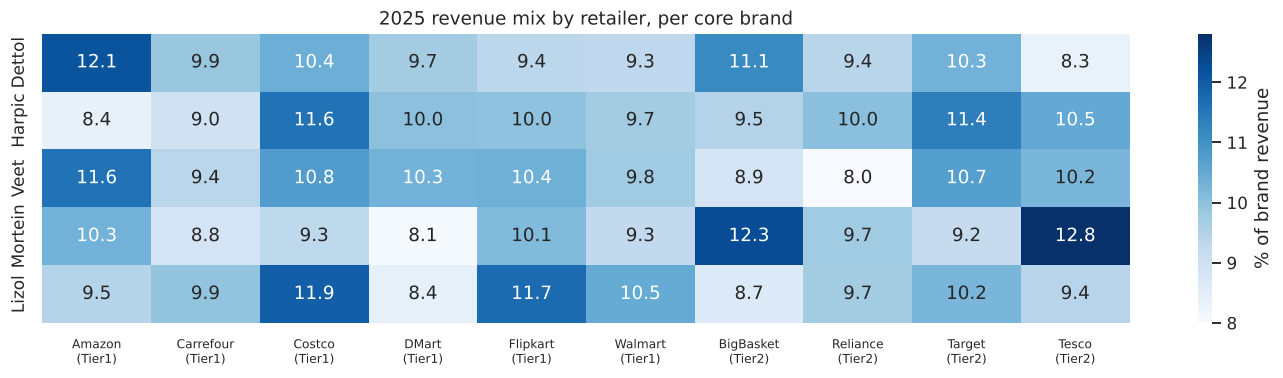

In [20]:
# Brand x Retailer: where each core brand's revenue comes from (share of the brand's revenue)
br = eng.breakdown("revenue", ["Brand", "Retailer"], Filters.make(brands=CORE_BRANDS), "YTD")
brp = br.pivot(index="Brand", columns="Retailer", values="value").loc[CORE_BRANDS]
brp = 100 * brp.div(brp.sum(axis=1), axis=0)
tiers = m.retailers.set_index("Retailer")["Tier"]
brp = brp[sorted(brp.columns, key=lambda r: (tiers[r], r))]
fig, ax = plt.subplots(figsize=(13, 3.6))
sns.heatmap(brp, annot=True, fmt=".1f", cmap="Blues", ax=ax, cbar_kws={"label": "% of brand revenue"})
ax.set_xticklabels([f"{r}\n({tiers[r]})" for r in brp.columns], rotation=0, fontsize=8)
ax.set_title("2025 revenue mix by retailer, per core brand"); ax.set_ylabel(""); ax.set_xlabel("")
plt.tight_layout()

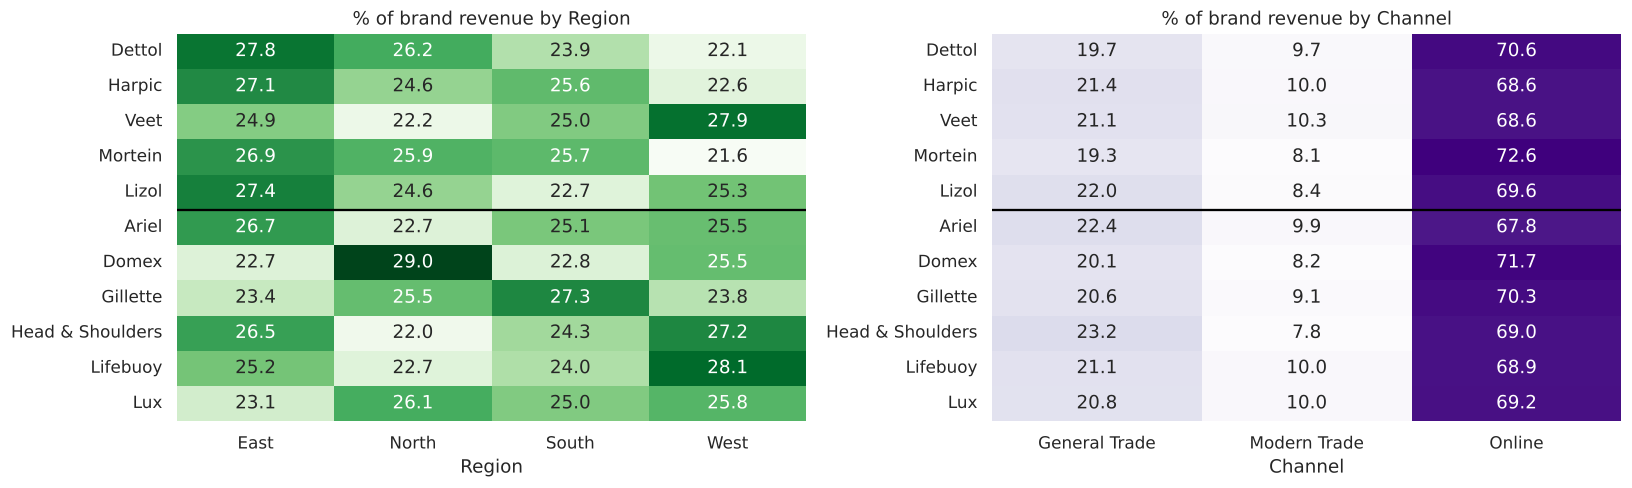

In [21]:
# Brand x Region and Brand x Channel (share of the brand's 2025 revenue)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
for a, dim, cmap in [(ax[0], "Region", "Greens"), (ax[1], "Channel", "Purples")]:
    b = eng.breakdown("revenue", ["Brand", dim], None, "YTD").pivot(index="Brand", columns=dim, values="value").loc[BRANDS]
    sns.heatmap(100 * b.div(b.sum(axis=1), axis=0), annot=True, fmt=".1f", cmap=cmap, ax=a, cbar=False)
    a.axhline(5, color="black", lw=1.5); a.set_title(f"% of brand revenue by {dim}"); a.set_ylabel("")
plt.tight_layout()

Spearman correlation, ASP vs units: -0.008


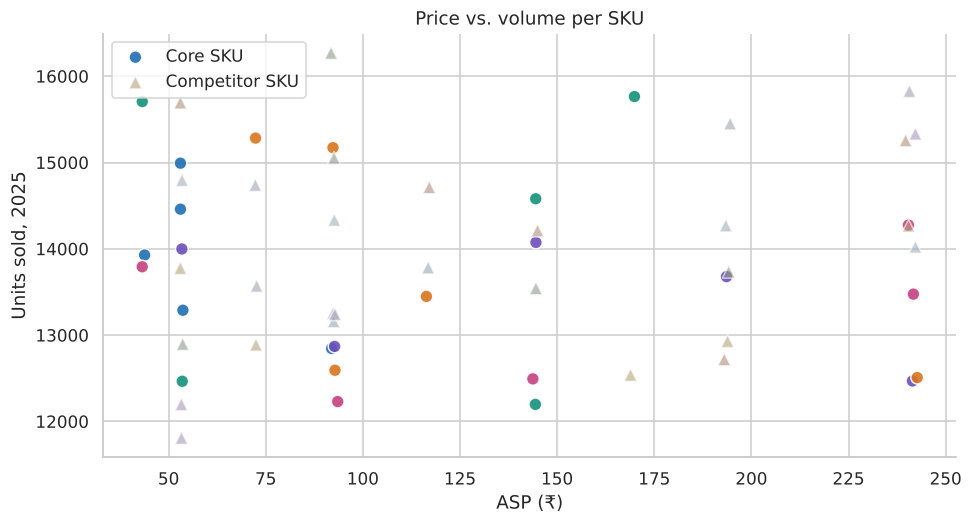

In [22]:
# Price vs. volume at SKU level: does a higher price mean fewer units?
sku = S[S["Date"].dt.year == 2025].groupby(["ProductID", "Brand", "SubCategory", "IsCore"]).agg(
    Revenue=("Revenue", "sum"), Units=("UnitsSold", "sum"), MRP=("MRP", "first")).reset_index()
sku["ASP"] = sku["Revenue"] / sku["Units"]
fig, ax = plt.subplots(figsize=(10, 5))
for core, mk in [(True, "o"), (False, "^")]:
    d = sku[sku["IsCore"] == core]
    ax.scatter(d["ASP"], d["Units"], c=[BRAND_COLORS[b] for b in d["Brand"]], marker=mk, s=70,
               alpha=0.9 if core else 0.6, edgecolor="white", label="Core SKU" if core else "Competitor SKU")
ax.set_xlabel("ASP (₹)"); ax.set_ylabel("Units sold, 2025"); ax.set_title("Price vs. volume per SKU"); ax.legend()
print("Spearman correlation, ASP vs units:", round(sku[["ASP", "Units"]].corr("spearman").iloc[0, 1], 3))

In [23]:
# Promotion effect, measured inside promo months only (promo vs. non-promo rows in the same months)
rows = []
for b in BRANDS:
    f = Filters.make(brands=b)
    rows.append([b, eng.value("promo_revenue_share", f, "ALL"), eng.value("promo_lift_pct", f, "ALL"),
                 eng.value("promo_revenue_lift_pct", f, "ALL")])
promo = pd.DataFrame(rows, columns=["Brand", "Promo revenue share %", "Unit lift % per txn", "Revenue lift % per txn"]).set_index("Brand")
by_promo = S[S["InPromoSeason"]].groupby("Promotion")[["UnitsSold", "Revenue"]].mean()
display(by_promo.rename(columns={"UnitsSold": "avg units / txn", "Revenue": "avg revenue / txn"}))
promo

,avg units / txn,avg revenue / txn
Promotion,,
Festive,83.83,"9,223.47"
None,79.95,"10,379.06"
Summer,76.91,"8,992.74"


,Promo revenue share %,Unit lift % per txn,Revenue lift % per txn
Brand,,,
Dettol,20.17,-3.22,-15.25
Harpic,21.06,2.35,-12.02
Veet,21.50,-2.21,-13.33
Mortein,18.80,3.22,-13.32
Lizol,19.68,3.97,-6.86
Ariel,20.35,1.90,-15.32
Domex,20.81,4.99,-8.76
Gillette,19.59,1.02,-10.18
Head & Shoulders,20.59,-1.40,-16.01


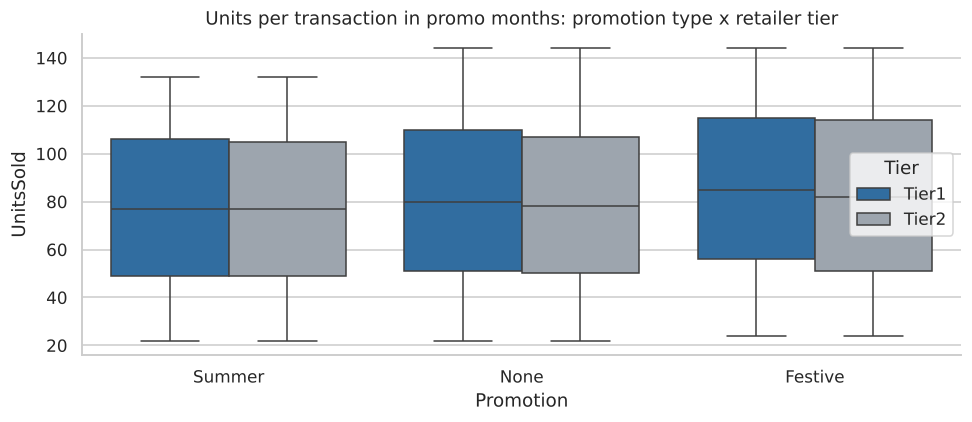

In [24]:
# Discount depth vs. units per transaction, by retailer tier
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=S[S["InPromoSeason"]], x="Promotion", y="UnitsSold", hue="Tier", ax=ax, palette=["#1F6FB2", "#9AA5B1"])
ax.set_title("Units per transaction in promo months: promotion type x retailer tier")
plt.tight_layout()

,avg_rating,leakage %,revenue YoY %
Dettol,3.41,11.95,-2.64
Harpic,3.47,0.00,-4.37
Veet,3.52,0.00,2.85
Mortein,3.50,0.00,-4.32
Lizol,3.54,0.00,-3.76
Ariel,3.46,0.00,-2.33
Domex,3.53,0.00,3.52
Gillette,3.47,0.00,6.31
Head & Shoulders,3.56,0.00,7.63
Lifebuoy,3.45,0.00,-7.04


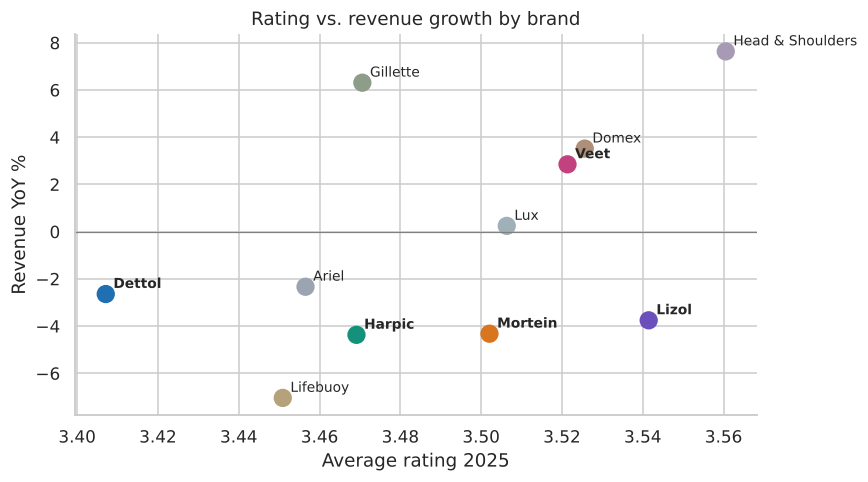

In [25]:
# Rating vs. growth: do better-rated brands grow faster?
rt = pd.DataFrame({b: {"avg_rating": eng.value("avg_rating", Filters.make(brands=b), "YTD"),
                       "leakage %": eng.value("leakage_complaint_pct", Filters.make(brands=b), "YTD"),
                       "revenue YoY %": yoy.loc[b, "Revenue YoY %"]} for b in BRANDS}).T
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(rt["avg_rating"], rt["revenue YoY %"], c=[BRAND_COLORS[b] for b in rt.index], s=120)
for b, r in rt.iterrows():
    ax.annotate(b, (r["avg_rating"], r["revenue YoY %"]), xytext=(5, 4), textcoords="offset points", fontsize=9,
                fontweight="bold" if b in CORE_BRANDS else "normal")
ax.axhline(0, color="grey", lw=0.8); ax.set_xlabel("Average rating 2025"); ax.set_ylabel("Revenue YoY %")
ax.set_title("Rating vs. revenue growth by brand")
rt.round(2)

In [26]:
# Margin % vs. ASP per brand
fin = pd.DataFrame({b: {"ASP": eng.value("asp", Filters.make(brands=b), "YTD"),
                        "Margin %": eng.value("margin_pct", Filters.make(brands=b), "YTD"),
                        "Revenue": eng.value("revenue", Filters.make(brands=b), "YTD")} for b in BRANDS}).T
fin.sort_values("Margin %", ascending=False)

,ASP,Margin %,Revenue
Dettol,58.51,46.50,"4,067,007.75"
Lifebuoy,146.38,46.25,"9,719,662.75"
Gillette,114.73,46.17,"8,202,655.50"
Head & Shoulders,146.64,45.74,"10,031,429.40"
Harpic,111.61,44.37,"7,892,087.60"
Mortein,119.93,44.05,"8,275,627.35"
Veet,154.30,43.89,"10,224,422.80"
Lizol,143.60,43.75,"9,633,878.75"
Lux,134.41,42.87,"9,499,961.45"
Domex,147.76,41.38,"10,726,714.85"


## 7. Multivariate analysis

Built on a **SKU × month panel** (55 SKUs × 24 months), so each row is one product in one month with all of its KPIs together.

(1320, 20)


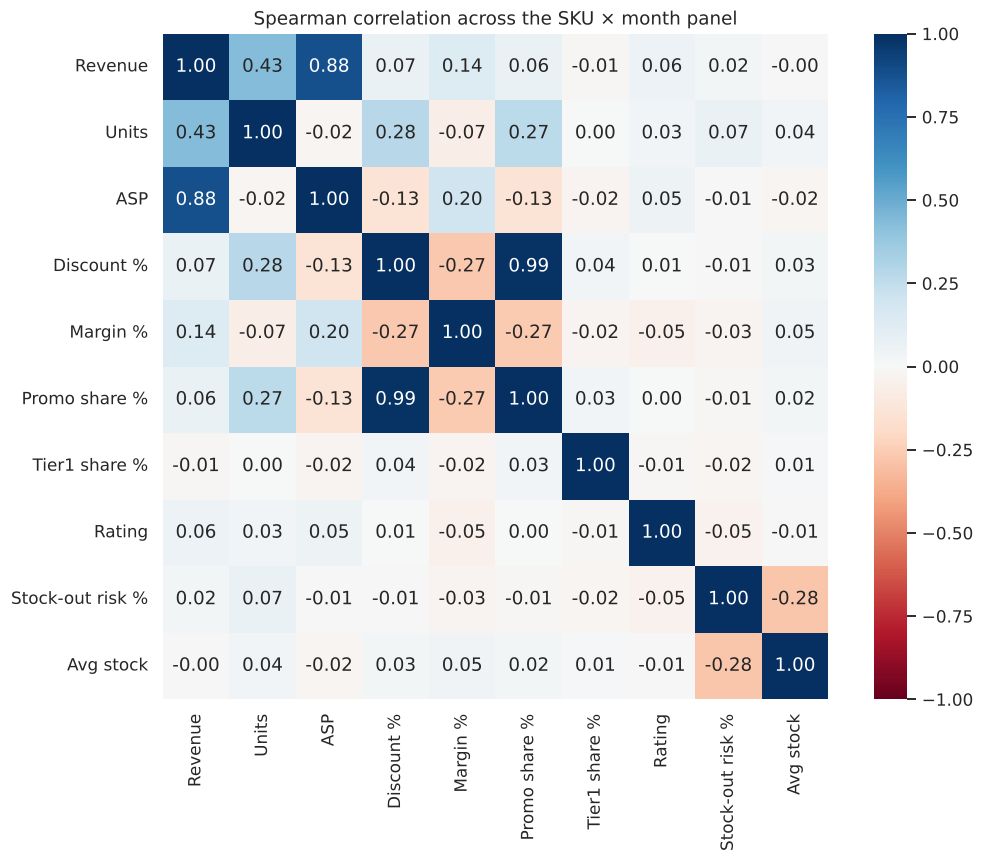

In [27]:
S2 = S.assign(month=S["Date"].dt.to_period("M"))
panel = S2.groupby(["ProductID", "Brand", "IsCore", "SubCategory", "month"]).agg(
    Revenue=("Revenue", "sum"), Units=("UnitsSold", "sum"), Gross=("GrossValue", "sum"), Disc=("DiscountValue", "sum"),
    Margin=("Margin", "sum"), PromoRev=("Revenue", lambda s: s[S2.loc[s.index, "HasPromo"]].sum()),
    T1=("Revenue", lambda s: s[S2.loc[s.index, "Tier"] == "Tier1"].sum())).reset_index()
panel["ASP"] = panel["Revenue"] / panel["Units"]
panel["Discount %"] = 100 * panel["Disc"] / panel["Gross"]
panel["Margin %"] = 100 * panel["Margin"] / panel["Revenue"]
panel["Promo share %"] = 100 * panel["PromoRev"] / panel["Revenue"]
panel["Tier1 share %"] = 100 * panel["T1"] / panel["Revenue"]
rv = m.reviews.assign(month=m.reviews["Date"].dt.to_period("M")).groupby(["ProductID", "month"])["Rating"].mean().rename("Rating")
iv = m.inventory.assign(month=m.inventory["Date"].dt.to_period("M")).groupby(["ProductID", "month"]).agg(
    **{"Stock-out risk %": ("BelowReorder", lambda s: 100 * s.mean()), "Avg stock": ("StockOnHand", "mean")})
panel = panel.join(rv, on=["ProductID", "month"]).join(iv, on=["ProductID", "month"])
feats = ["Revenue", "Units", "ASP", "Discount %", "Margin %", "Promo share %", "Tier1 share %", "Rating", "Stock-out risk %", "Avg stock"]
print(panel.shape)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(panel[feats].corr("spearman"), annot=True, fmt=".2f", cmap="RdBu", center=0, vmin=-1, vmax=1, ax=ax, square=True)
ax.set_title("Spearman correlation across the SKU × month panel"); plt.tight_layout()

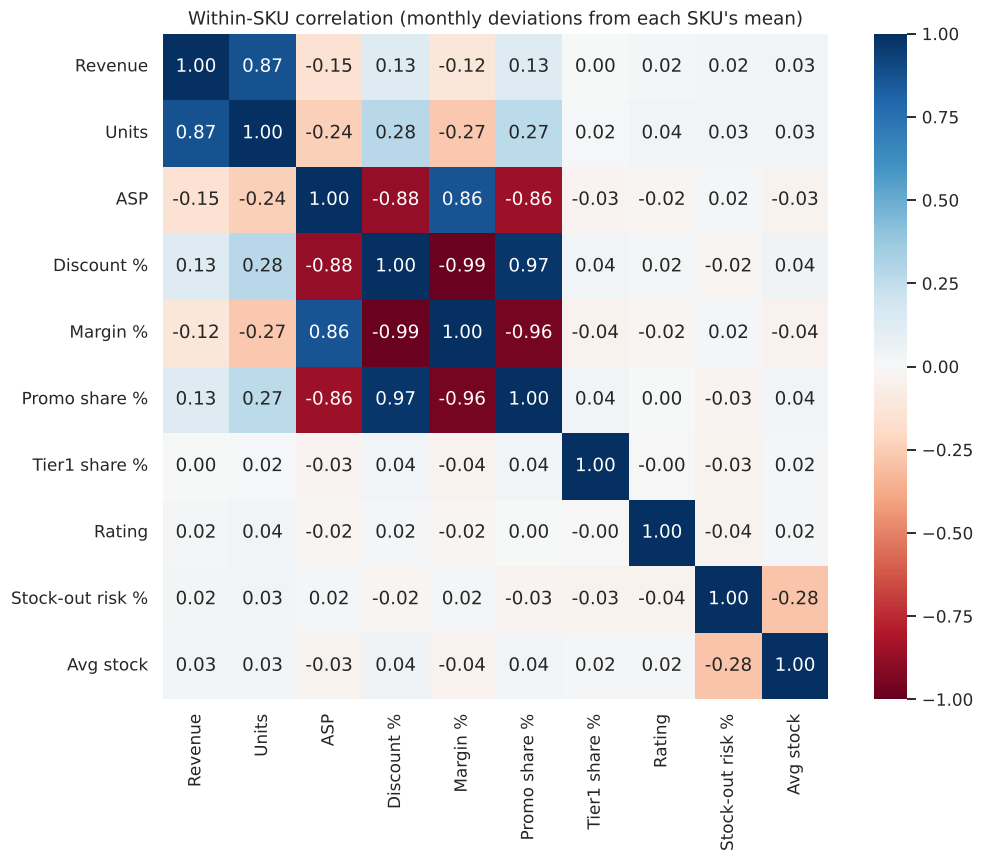

In [28]:
# Same correlations, but within each SKU (each SKU's monthly deviations from its own average):
# removes the "expensive SKUs sell fewer units" effect and shows what moves together over time
within = panel.copy()
within[feats] = within.groupby("ProductID")[feats].transform(lambda s: s - s.mean())
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(within[feats].corr(), annot=True, fmt=".2f", cmap="RdBu", center=0, vmin=-1, vmax=1, ax=ax, square=True)
ax.set_title("Within-SKU correlation (monthly deviations from each SKU's mean)"); plt.tight_layout()

In [29]:
# Explaining monthly units per SKU with several factors at once (within-SKU OLS with standardised inputs).
# Coefficients = change in units for a 1-standard-deviation change in each factor, holding the others fixed.
X_cols = ["Discount %", "Tier1 share %", "Rating", "Stock-out risk %"]
d = within.dropna(subset=X_cols + ["Units"])
X = (d[X_cols] - d[X_cols].mean()) / d[X_cols].std()
X.insert(0, "const", 1.0)
coef, *_ = np.linalg.lstsq(X.to_numpy(), d["Units"].to_numpy(), rcond=None)
pred = X.to_numpy() @ coef
r2 = 1 - ((d["Units"] - pred) ** 2).sum() / ((d["Units"] - d["Units"].mean()) ** 2).sum()
print(f"Within-SKU R² = {r2:.3f} on {len(d):,} SKU-months")
pd.Series(coef[1:], index=X_cols, name="units per 1 SD").round(1).to_frame()

Within-SKU R² = 0.083 on 1,291 SKU-months


,units per 1 SD
Discount %,92.70
Tier1 share %,0.70
Rating,11.30
Stock-out risk %,10.50


In [30]:
# Brand x SubCategory x Retailer tier: 2025 revenue for the core brands
cube = eng.breakdown("revenue", ["Brand", "SubCategory", "Tier"], Filters.make(brands=CORE_BRANDS), "YTD")
cp = cube.pivot_table(index=["Brand", "SubCategory"], columns="Tier", values="value", fill_value=0)
cp["Tier1 %"] = 100 * cp["Tier1"] / cp.sum(axis=1)
cp

Tier                       Tier1        Tier2  Tier1 %
Brand   SubCategory                                   
Dettol  Cleaner     1,520,979.00 1,037,502.50    59.45
        Liquid        478,368.00   316,932.00    60.15
        Soap          473,079.75   240,146.50    66.33
Harpic  Cream       1,430,500.75 1,009,630.90    58.62
        Spray       3,196,769.90 2,255,186.05    58.64
Lizol   Cleaner       420,884.75   326,782.50    56.29
        Liquid      1,639,959.00 1,007,994.70    61.93
        Soap        1,820,053.05 1,190,643.30    60.45
        Spray       2,086,891.35 1,140,670.10    64.66
Mortein Cleaner       701,160.00   404,880.00    63.39
        Cream       3,032,348.45 2,572,540.90    54.10
        Spray         899,064.00   665,634.00    57.46
Veet    Cleaner     2,236,032.45 1,195,922.10    65.15
        Soap        3,524,890.55 2,123,820.45    62.40
        Spray         597,322.00   546,435.25    52.22

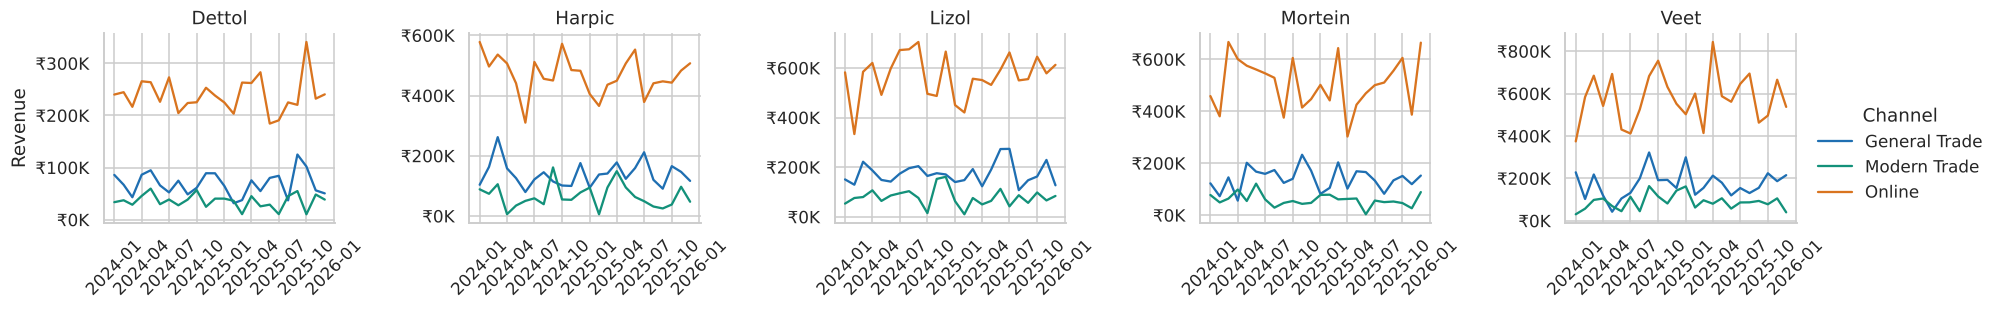

In [31]:
# Small multiples: monthly revenue per core brand split by retailer channel
ch = eng.timeseries("revenue", "M", Filters.make(brands=CORE_BRANDS), "ALL", by=["Brand", "Channel"])
g = sns.relplot(data=ch, x="bucket", y="value", hue="Channel", col="Brand", kind="line", col_wrap=5, height=2.8, aspect=1.2,
                palette=["#1F6FB2", "#13917A", "#D9741F"], facet_kws={"sharey": False})
g.set_axis_labels("", "Revenue"); g.set_titles("{col_name}")
for ax in g.axes.flat:
    ax.yaxis.set_major_formatter(inr); ax.tick_params(axis="x", rotation=45)

## 8. Competitive landscape preview (SubCategory rule)

A core variant competes with every SKU in the **same SubCategory**, and Category is ignored. Phase 2 builds the full 3-tier mapping: same brand, other Reckitt brands, external. This preview counts, for each core brand, how many of its 5 variants face each external brand.

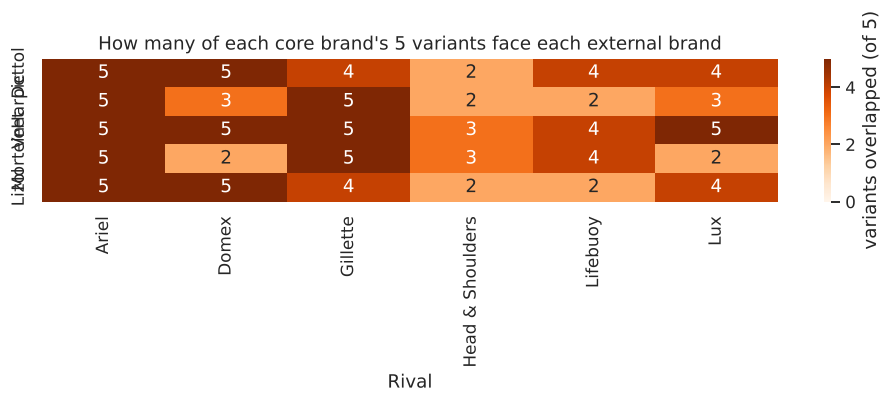

In [32]:
P = m.products
ext = P[~P["IsCore"]]
rows = []
for b in CORE_BRANDS:
    for _, v in P[P["Brand"] == b].iterrows():
        rivals = ext[ext["SubCategory"] == v["SubCategory"]]["Brand"].unique()
        for r in rivals:
            rows.append([b, v["ProductID"], r])
ov = pd.DataFrame(rows, columns=["Core brand", "Variant", "Rival"]).drop_duplicates()
overlap = ov.groupby(["Core brand", "Rival"])["Variant"].nunique().unstack(fill_value=0).loc[CORE_BRANDS]
fig, ax = plt.subplots(figsize=(9, 3.6))
sns.heatmap(overlap, annot=True, fmt="d", cmap="Oranges", vmin=0, vmax=5, ax=ax, cbar_kws={"label": "variants overlapped (of 5)"})
ax.set_title("How many of each core brand's 5 variants face each external brand"); ax.set_ylabel("")
plt.tight_layout()

In [33]:
# Head to head at SubCategory level, 2025: each core brand's ASP vs. external rivals' ASP in the same SubCategory
rows = []
for b in CORE_BRANDS:
    for sc in P[P["Brand"] == b]["SubCategory"].unique():
        own = eng.value("asp", Filters.make(brands=b, subcategories=sc), "YTD")
        rv_ = eng.value("asp", Filters.make(brands=list(ext["Brand"].unique()), subcategories=sc), "YTD")
        rd = eng.value("discount_pct", Filters.make(brands=list(ext["Brand"].unique()), subcategories=sc), "YTD")
        rows.append([b, sc, own, rv_, 100 * (own / rv_ - 1), eng.value("discount_pct", Filters.make(brands=b, subcategories=sc), "YTD"), rd])
pd.DataFrame(rows, columns=["Brand", "SubCategory", "Our ASP", "Rival ASP", "Price gap %", "Our discount %", "Rival discount %"]).set_index(["Brand", "SubCategory"])

Our ASP  Rival ASP  Price gap %  Our discount %  Rival discount %
Brand   SubCategory                                                                   
Dettol  Liquid         53.05      99.71       -46.80            3.55              2.75
        Cleaner        62.05      98.12       -36.76            3.17              2.90
        Soap           53.67     169.71       -68.37            2.41              2.93
Harpic  Spray         127.36     140.86        -9.58            2.93              2.84
        Cream          87.45     122.66       -28.70            3.33              3.16
Veet    Soap          142.07     169.71       -16.29            3.23              2.93
        Cleaner       240.42      98.12       145.02            3.45              2.90
        Spray          93.52     140.86       -33.61            1.56              2.84
Mortein Cream         139.17     122.66        13.47            2.56              3.16
        Spray         116.35     140.86       -17.40            3.04              2.84
        Cleaner        72.37      98.12       -26.24            3.51              2.90
Lizol   Liquid        193.59      99.71        94.16            2.72              2.75
        Spray         119.79     140.86       -14.95            2.77              2.84
        Cleaner        53.41      98.12       -45.56            2.89              2.90
        Soap          241.45     169.71        42.27            3.03              2.93

,2025 avg share,2024 avg share,change (pp)
Dettol,24.49,23.91,0.58
Harpic,18.12,17.94,0.18
Veet,13.94,13.89,0.04
Domex,11.04,11.00,0.04
Lifebuoy,19.96,20.00,-0.04
Ariel,13.02,13.06,-0.04


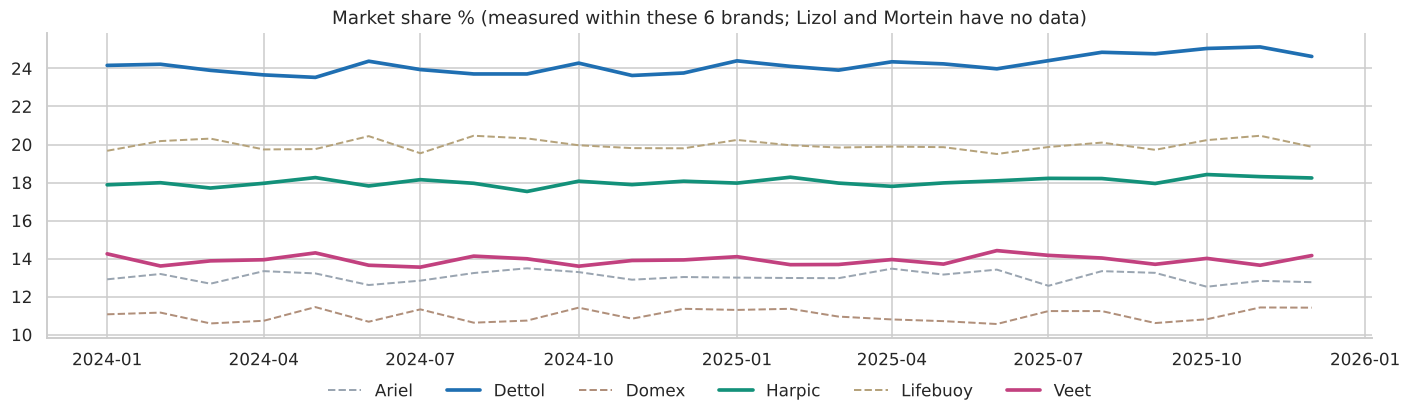

In [34]:
# Market share (6 brands with data), monthly
ms = m.market_share.pivot(index="Date", columns="Brand", values="MarketSharePct")
fig, ax = plt.subplots(figsize=(13, 4))
for b in ms.columns:
    core = b in CORE_BRANDS
    ax.plot(ms.index, ms[b], color=BRAND_COLORS[b], lw=2.4 if core else 1.3, ls="-" if core else "--", label=b)
ax.set_title("Market share % (measured within these 6 brands; Lizol and Mortein have no data)")
ax.legend(ncol=6, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1)); plt.tight_layout()
share_change = pd.DataFrame({b: eng.compare("market_share", Filters.make(brands=b), "YTD", "yoy") for b in ms.columns}).T[["current", "previous", "delta"]]
share_change.columns = ["2025 avg share", "2024 avg share", "change (pp)"]
share_change.astype(float).sort_values("change (pp)", ascending=False)

In [35]:
# Competitor events by manufacturer and type
ev = m.events.assign(year=m.events["Date"].dt.year)
pd.crosstab([ev["Competitor"], ev["year"]], ev["Event"], margins=True)

Event            New Launch  Price Cut  TV Campaign  All
Competitor year                                         
P&G        2024           4          0            0    4
           2025           5          2            6   13
SC Johnson 2024           0          6            2    8
           2025           1          1            2    4
Unilever   2024           3          3            4   10
           2025           3          3            6   12
All                      16         15           20   51

## 9. Brand Health Score

| Component | Measure | Weight |
|---|---|---|
| Growth | Revenue YoY % | 30% |
| Margin | Margin % | 25% |
| Rating | Average rating | 25% |
| Position | Market share change in pp (**real**, 6 brands) or Premium Retailer Share change in pp (**proxy**, 5 brands) | 20% |

Each component becomes a z-score, then a 0–100 score (50 = average brand). **The position component is standardised within its own source group**, so the real-share and proxy brands are never ranked on each other's scales.

In [36]:
hs = health_scores(eng, "YTD", "yoy")
cols = ["IsCore", "growth", "margin", "rating", "position", "position_source",
        "growth_score", "margin_score", "rating_score", "position_score", "health_score", "rank"]
hs[cols].style.format(precision=2).background_gradient(subset=["health_score"], cmap="RdYlGn", vmin=20, vmax=80)

,IsCore,growth,margin,rating,position,position_source,growth_score,margin_score,rating_score,position_score,health_score,rank
Brand,,,,,,,,,,,,
Head & Shoulders,False,7.63,45.74,3.56,-3.43,proxy,95.90,77.60,94.40,25.00,76.80,1
Gillette,False,6.31,46.17,3.47,-0.77,proxy,92.70,82.50,31.10,58.20,67.80,2
Veet,True,2.85,43.89,3.52,0.04,real,75.80,49.90,75.20,35.10,61.00,3
Lizol,True,-3.76,43.75,3.54,2.06,proxy,22.90,47.70,87.40,87.30,58.10,4
Lux,False,0.24,42.87,3.51,1.28,proxy,55.20,33.70,63.00,81.10,57.00,5
Domex,False,3.52,41.38,3.53,0.04,real,80.10,15.10,78.20,33.50,54.10,6
Dettol,True,-2.64,46.50,3.41,0.58,real,30.90,85.80,2.50,98.20,51.00,7
Harpic,True,-4.37,44.37,3.47,0.18,real,19.10,57.70,29.90,59.50,39.50,8
Mortein,True,-4.32,44.05,3.50,-6.10,proxy,19.30,52.60,59.20,6.00,34.90,9


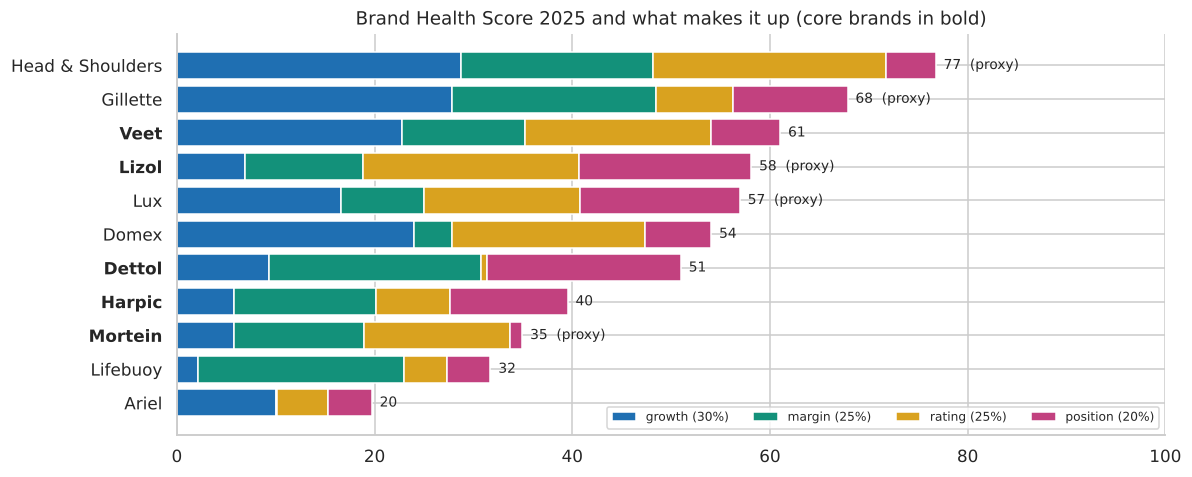

In [37]:
fig, ax = plt.subplots(figsize=(11, 4.5))
order = hs.index.tolist()
left = np.zeros(len(order))
from kpi.health_score import WEIGHTS
for comp, col in zip(WEIGHTS, ["#1F6FB2", "#13917A", "#D9A21F", "#C2417F"]):
    vals = (hs[f"{comp}_score"] * WEIGHTS[comp]).to_numpy()
    ax.barh(order, vals, left=left, color=col, label=f"{comp} ({int(WEIGHTS[comp]*100)}%)")
    left += vals
for i, b in enumerate(order):
    ax.text(left[i] + 0.8, i, f"{left[i]:.0f}" + ("  (proxy)" if hs.loc[b, "position_source"] == "proxy" else ""), va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.legend(ncol=4, loc="lower right", fontsize=8)
for t in ax.get_yticklabels():
    t.set_fontweight("bold" if t.get_text() in CORE_BRANDS else "normal")
ax.set_title("Brand Health Score 2025 and what makes it up (core brands in bold)"); plt.tight_layout()

## 10. Key findings

Generated from the numbers above, so they stay correct if the data changes.

In [38]:
core = yoy[yoy["Type"] == "Core"]
comp = yoy[yoy["Type"] == "Competitor"]
best_hs = hs[hs["IsCore"]].iloc[0]; worst_hs = hs[hs["IsCore"]].iloc[-1]
r_core = eng.compare("revenue", Filters.make(brands=CORE_BRANDS), "YTD", "yoy")
r_comp = eng.compare("revenue", Filters.make(brands=list(COMP_COLORS)), "YTD", "yoy")
avg_lift = eng.value("promo_lift_pct", None, "ALL"); avg_rev_lift = eng.value("promo_revenue_lift_pct", None, "ALL")
findings = [
    f"Core brands' 2025 revenue changed {r_core['delta_pct']:+.1f}% YoY, vs {r_comp['delta_pct']:+.1f}% for the competitor brands.",
    "Growing core brands: " + (", ".join(f"{b} ({v:+.1f}%)" for b, v in core["Revenue YoY %"].items() if v > 0) or "none")
      + ". Shrinking: " + ", ".join(f"{b} ({v:+.1f}%)" for b, v in core["Revenue YoY %"].items() if v <= 0) + ".",
    f"Fastest-growing competitor: {comp['Revenue YoY %'].idxmax()} ({comp['Revenue YoY %'].max():+.1f}%).",
    f"Promotions barely move volume: units per promo transaction are {avg_lift:+.1f}% vs non-promo rows in the same months, "
      f"while the 10-15% discount makes revenue per promo transaction {avg_rev_lift:+.1f}%. Promotions cost revenue in this data.",
    (lambda lk: f"Packaging leakage complaints appear only for Dettol: {int(lk.sum())} reviews, all in "
      f"{', '.join(map(str, lk.index))}, spread across all 5 Dettol SKUs (worst: Liquid). A contained quality incident, not a "
      f"steady pattern.")(m.reviews[m.reviews['IsLeakage']].groupby(m.reviews['Date'].dt.to_period('Q')).size()),
    f"Highest core Health Score: {best_hs.name} ({best_hs['health_score']:.0f}); lowest: {worst_hs.name} ({worst_hs['health_score']:.0f}).",
    f"Market share 2025 vs 2024 (pp): " + ", ".join(f"{b} {v:+.2f}" for b, v in share_change['change (pp)'].astype(float).items()) + ".",
    f"Lizol and Mortein have no market-share data; their Health Score position uses the labelled Premium Retailer Share proxy.",
    f"Campaign spend and ROI cannot be split by brand (no Brand column); competitor events are only known per manufacturer.",
]
for i, f_ in enumerate(findings, 1):
    print(f"{i}. {f_}")

1. Core brands' 2025 revenue changed -2.3% YoY, vs +1.2% for the competitor brands.
2. Growing core brands: Veet (+2.9%). Shrinking: Dettol (-2.6%), Harpic (-4.4%), Mortein (-4.3%), Lizol (-3.8%).
3. Fastest-growing competitor: Head & Shoulders (+7.6%).
4. Promotions barely move volume: units per promo transaction are +1.3% vs non-promo rows in the same months, while the 10-15% discount makes revenue per promo transaction -12.1%. Promotions cost revenue in this data.
5. Packaging leakage complaints appear only for Dettol: 27 reviews, all in 2025Q2, spread across all 5 Dettol SKUs (worst: Liquid). A contained quality incident, not a steady pattern.
6. Highest core Health Score: Veet (61); lowest: Mortein (35).
7. Market share 2025 vs 2024 (pp): Ariel -0.04, Dettol +0.58, Domex +0.04, Harpic +0.18, Lifebuoy -0.04, Veet +0.04.
8. Lizol and Mortein have no market-share data; their Health Score position uses the labelled Premium Retailer Share proxy.
9. Campaign spend and ROI cannot be spli

**Next: Phase 2** builds the per-variant 3-tier competitor mapping, the competitor KPIs (Price Gap, Discount Gap, Market Share Gap, Competitor Activity Index) for a selected core brand, and the Diagnostics engine that explains why revenue moved.